# 26 Nov

## Raw Data

PMT - 0.44-0.45
TA Current: 1 A
Cell temp: 120 .94 C (in loop)

LCVR

Temp - 40 C

	1. 1.26 V - 24.45 +/- 0.1
	2. 1.135 V - 21.7 +/- 0.17
	3. 1.12 V - 21.5 +/- 0.1
	4. 1.35 - 26.2 +/- 0.145 mw
	5. 1.45 V - 28.6 +/- 0.700

Frequency slope = -3234.446 ± 90.969 Hz/mW
Fractional coefficient K_P = -8.394994e-12 ± 2.361090e-13 per mW
Fractional coefficient K_P = -8.394994e-09 ± 2.361090e-10 per W
Chi-squared = 6.170
Degrees of freedom = 3
Reduced chi-squared = 2.057

At P0 = 24.45 mW:
  K_P P0 = -2.052576e-10 ± 5.772864e-12


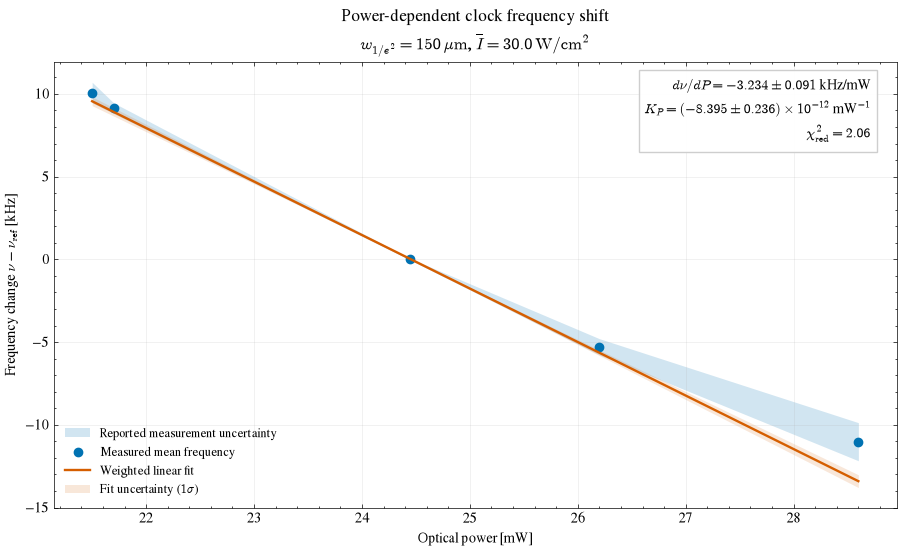

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
import scienceplots 
plt.style.use(["science", "no-latex"])
# Columns: optical power [mW], mean frequency [Hz], frequency error [Hz].
data = np.array([
    [24.45, 385282661486234.00,   47.9520744],
    [21.70, 385282661495370.00,  320.473936],
    [21.50, 385282661496320.00,  618.900749],
    [26.20, 385282661480952.00,  489.203695],
    [28.60, 385282661475213.00, 1152.37681],
], dtype=np.float64)

power_mw, frequency_hz, frequency_error_hz = data.T

# Fixed offsets improve numerical conditioning.
reference_frequency_hz = 385282661486234.00
reference_power_mw = 24.45

frequency_change_hz = frequency_hz - reference_frequency_hz


def linear_model(power, slope, offset):
    """Frequency change [Hz] versus optical power [mW]."""
    return slope * (power - reference_power_mw) + offset


# Treat the supplied errors as independent 1-sigma uncertainties.
parameters, covariance = curve_fit(
    linear_model,
    power_mw,
    frequency_change_hz,
    sigma=frequency_error_hz,
    absolute_sigma=True,
    p0=(-3200.0, 0.0),
)

slope_hz_per_mw, offset_hz = parameters
slope_error_hz_per_mw, offset_error_hz = np.sqrt(np.diag(covariance))

# Fractional-frequency sensitivity per unit ABSOLUTE optical power.
k_fractional_per_mw = slope_hz_per_mw / reference_frequency_hz
k_error_per_mw = slope_error_hz_per_mw / reference_frequency_hz

# Fit diagnostics.
residuals_hz = frequency_change_hz - linear_model(power_mw, *parameters)
chi_squared = np.sum((residuals_hz / frequency_error_hz)**2)
degrees_of_freedom = len(power_mw) - len(parameters)
reduced_chi_squared = chi_squared / degrees_of_freedom

print(
    f"Frequency slope = {slope_hz_per_mw:.3f} "
    f"± {slope_error_hz_per_mw:.3f} Hz/mW"
)
print(
    f"Fractional coefficient K_P = {k_fractional_per_mw:.6e} "
    f"± {k_error_per_mw:.6e} per mW"
)
print(
    f"Fractional coefficient K_P = {k_fractional_per_mw * 1e3:.6e} "
    f"± {k_error_per_mw * 1e3:.6e} per W"
)
print(f"Chi-squared = {chi_squared:.3f}")
print(f"Degrees of freedom = {degrees_of_freedom}")
print(f"Reduced chi-squared = {reduced_chi_squared:.3f}")

# For the earlier ADEV calculation:
# delta_nu / nu = (K_P * P0) * (delta_P / P0).
P0_mw = 24.45  # Set to the mean cell power of the relevant ADEV recording.
kp_p0 = k_fractional_per_mw * P0_mw
kp_p0_error = k_error_per_mw * P0_mw  # Excludes uncertainty in P0.

print(
    f"\nAt P0 = {P0_mw:g} mW:"
    f"\n  K_P P0 = {kp_p0:.6e} ± {kp_p0_error:.6e}"
)


# ============================================================
# PLOT
# ============================================================

order = np.argsort(power_mw)
power_sorted = power_mw[order]
change_sorted_khz = frequency_change_hz[order] / 1e3
error_sorted_khz = frequency_error_hz[order] / 1e3

power_fit = np.linspace(power_sorted.min(), power_sorted.max(), 400)
frequency_fit_hz = linear_model(power_fit, *parameters)

# Propagate the slope–offset covariance to the fitted mean line.
dx = power_fit - reference_power_mw
fit_variance_hz2 = (
    covariance[0, 0] * dx**2
    + 2 * covariance[0, 1] * dx
    + covariance[1, 1]
)
fit_error_hz = np.sqrt(np.maximum(fit_variance_hz2, 0))

fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")

if hasattr(fig.canvas, "header_visible"):
    fig.canvas.header_visible = False

# Supplied measurement uncertainties.
ax.fill_between(
    power_sorted,
    change_sorted_khz - error_sorted_khz,
    change_sorted_khz + error_sorted_khz,
    color="#0072B2",
    alpha=0.18,
    linewidth=0,
    label="Reported measurement uncertainty",
)

ax.plot(
    power_sorted,
    change_sorted_khz,
    color="#0072B2",
    marker="o",
    linestyle="none",
    markersize=6,
    label="Measured mean frequency",
)

# Weighted straight-line fit.
ax.plot(
    power_fit,
    frequency_fit_hz / 1e3,
    color="#D55E00",
    linewidth=1.7,
    label="Weighted linear fit",
)

# Uncertainty of the fitted mean, not a prediction interval.
ax.fill_between(
    power_fit,
    (frequency_fit_hz - fit_error_hz) / 1e3,
    (frequency_fit_hz + fit_error_hz) / 1e3,
    color="#D55E00",
    alpha=0.15,
    linewidth=0,
    label=r"Fit uncertainty ($1\sigma$)",
)

annotation = (
    rf"$d\nu/dP = {slope_hz_per_mw / 1e3:.3f}"
    rf"\pm {slope_error_hz_per_mw / 1e3:.3f}$ kHz/mW"
    "\n"
    rf"$K_P = ({k_fractional_per_mw / 1e-12:.3f}"
    rf"\pm {k_error_per_mw / 1e-12:.3f})"
    rf"\times10^{{-12}}$ mW$^{{-1}}$"
    "\n"
    rf"$\chi^2_\mathrm{{red}}={reduced_chi_squared:.2f}$"
)

ax.text(
    0.97,
    0.97,
    annotation,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10,
    bbox=dict(facecolor="white", edgecolor="0.8", alpha=0.95),
)

beam_radius_um = 150.0
beam_radius_m = beam_radius_um * 1e-6
mean_power_w = np.mean(power_mw) * 1e-3

# Spatial average inside the Gaussian beam's 1/e² radius,
# evaluated at the mean power of the measurements.
average_intensity_w_cm2 = (
    mean_power_w * (1 - np.exp(-2))
    / (np.pi * beam_radius_m**2)
    / 1e4
)

ax.set(
    title=(
        "Power-dependent clock frequency shift\n"
        rf"$w_{{1/e^2}}={beam_radius_um:g}\,\mu\mathrm{{m}}$, "
        rf"$\overline{{I}}={average_intensity_w_cm2:.1f}"
        rf"\,\mathrm{{W/cm^2}}$"
    ),
    xlabel="Optical power [mW]",
    ylabel=r"Frequency change $\nu-\nu_{\mathrm{ref}}$ [kHz]",
)

ax.grid(True, alpha=0.25)
ax.legend(loc="lower left", fontsize=9)

plt.show()